# 📊 01 — EDA: Bitext Customer Support Dataset

**EDA (Exploratory Data Analysis)** = model banane se pehle data ko achhe se samajhna.

Is notebook mein hum ye karenge:
1. Data load karke dekhna (kitni rows, kaunse columns)
2. Missing values aur duplicates check karna
3. Category distribution (imbalance) dekhna
4. `{{Order Number}}` jaise placeholders ko samajhna aur saaf karna
5. Message length aur har category ke common words dekhna
6. Saaf (clean) data save karna → `ml/data/bitext_clean.csv` (training isi se hogi)

> 💡 Har cell ko upar se neeche ek-ek karke chalao (`Shift + Enter`).

## 1️⃣ Setup — libraries import karna aur file ka path dhoondhna

- **pandas** → table (DataFrame) ke saath kaam karne ke liye
- **numpy** → numbers / maths
- **matplotlib + seaborn** → graphs
- `ROOT` wala loop project ka main folder dhoondhta hai, taaki notebook kahin se bhi chalao, path sahi rahe.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

# Project root dhoondho (jis folder ke andar ml/data hai)
ROOT = Path.cwd()
while not (ROOT / "ml" / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

DATA_PATH = ROOT / "ml" / "data" / "bitext.csv"
CLEAN_PATH = ROOT / "ml" / "data" / "bitext_clean.csv"
print("Data file:", DATA_PATH, "| exists:", DATA_PATH.exists())

Data file: D:\Capstone project\ml\data\bitext.csv | exists: True


## 2️⃣ Data load karna aur pehli jhalak

Columns ka matlab:
| Column | Matlab | Hamare liye |
|---|---|---|
| `instruction` | Customer ka message | ✅ **Input (X)** |
| `category` | Message kis type ka hai (ORDER, REFUND…) | ✅ **Output / label (y)** |
| `intent` | Category ke andar exact irada (cancel_order, track_refund…) | Extra info |
| `response` | Sample jawab | Use nahi karenge (RAG apne docs se jawab dega) |
| `flags` | Language variation tags (typos, casual language, etc.) | Sirf samajhne ke liye |

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (26872, 5)


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,"I've understood you have a question regarding canceling order {{Order Number}}, and I'm here to provide you with the..."
1,BQZ,i have a question about cancelling oorder {{Order Number}},ORDER,cancel_order,I've been informed that you have a question about canceling order {{Order Number}}. I'm here to assist you! Please g...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance with canceling your purchase with the purchase number {{Order Number}}. I...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with canceling your purchase with the order number {{Order Number}}. We apolog...
4,BCELN,"I cannot afford this order, cancel purchase {{Order Number}}",ORDER,cancel_order,I'm sensitive to the fact that you're facing financial difficulties and need to cancel your purchase with the order ...


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   flags        26872 non-null  str  
 1   instruction  26872 non-null  str  
 2   category     26872 non-null  str  
 3   intent       26872 non-null  str  
 4   response     26872 non-null  str  
dtypes: str(5)
memory usage: 1.0 MB


## 3️⃣ Missing values (khaali cells)
Agar kisi row mein message ya category khaali ho, to wo training ke kaam ki nahi.

In [4]:
df.isnull().sum()

flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64

## 4️⃣ Category distribution — kya data **balanced** hai?

Agar ek category ke bahut zyada examples hon aur dusri ke kam, to model badi category ki taraf jhuk sakta hai.
Isko **class imbalance** kehte hain.

category
ACCOUNT         5986
ORDER           3988
REFUND          2992
INVOICE         1999
CONTACT         1999
PAYMENT         1998
FEEDBACK        1997
DELIVERY        1994
SHIPPING        1970
SUBSCRIPTION     999
CANCEL           950
Name: count, dtype: int64

Sabse badi / sabse chhoti category ratio: 6.3


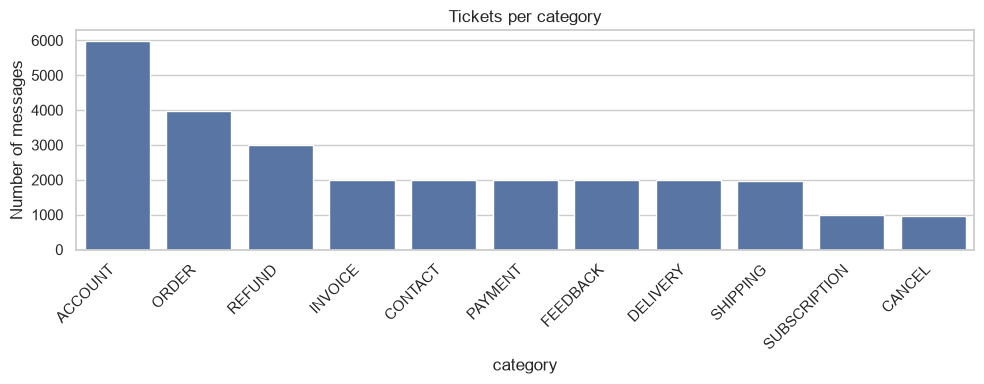

In [5]:
cat_counts = df["category"].value_counts()
print(cat_counts)
print("\nSabse badi / sabse chhoti category ratio:", round(cat_counts.max() / cat_counts.min(), 1))

plt.figure(figsize=(10, 4))
sns.barplot(x=cat_counts.index, y=cat_counts.values, color="#4C72B0")
plt.title("Tickets per category")
plt.ylabel("Number of messages")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**📝 Observation:** ACCOUNT sabse badi aur CANCEL sabse chhoti category hai (~6x farak).

**Training mein iska ilaaj:**
- **Stratified split** → train aur test mein har category ka same ratio
- **`class_weight="balanced"`** → chhoti category ki galti ko zyada weight
- **Macro F1** → har category ko barabar importance dene wala metric

## 5️⃣ Har category ke andar kitne intents hain?

In [6]:
intents_per_cat = df.groupby("category")["intent"].unique()
for cat, intents in intents_per_cat.items():
    print(f"{cat:<14} → {', '.join(sorted(intents))}")

ACCOUNT        → create_account, delete_account, edit_account, recover_password, registration_problems, switch_account
CANCEL         → check_cancellation_fee
CONTACT        → contact_customer_service, contact_human_agent
DELIVERY       → delivery_options, delivery_period
FEEDBACK       → complaint, review
INVOICE        → check_invoice, get_invoice
ORDER          → cancel_order, change_order, place_order, track_order
PAYMENT        → check_payment_methods, payment_issue
REFUND         → check_refund_policy, get_refund, track_refund
SHIPPING       → change_shipping_address, set_up_shipping_address
SUBSCRIPTION   → newsletter_subscription


## 6️⃣ Flags column — language variations
Dataset banane walon ne messages mein jaan-boojh ke variations daale hain (typos, casual tone, alag sentence structure).
Isse model "messy" real-world messages bhi samajhna seekhta hai.

In [7]:
df["flags"].value_counts().head(15)

flags
BL       5212
BLQ      2467
BIL      2138
BLM      1297
BILQ     1057
BLQZ      970
BLZ       902
BKL       862
BLMQ      600
BEL       533
BILM      521
BCL       484
BCIL      427
BILQZ     412
BILP      363
Name: count, dtype: int64

## 7️⃣ Duplicates check

Do tarah ke duplicates dekhenge:
1. **Same message + same category** → bas extra copy hai, hata do
2. **Same message + alag category** → ⚠️ *conflicting label*. Model confuse hoga, ye bhi hatani padengi

**Kyun zaroori?** Agar same message train aur test dono mein chala gaya, to model ka score fake-high aayega
(usne jawab "ratta" maar liya). Isko **data leakage** kehte hain.

In [8]:
print("Total rows:", len(df))
print("Exact duplicate (message + category):", df.duplicated(subset=["instruction", "category"]).sum())

labels_per_msg = df.groupby("instruction")["category"].nunique()
conflicting_msgs = labels_per_msg[labels_per_msg > 1].index
print("Messages with conflicting categories:", len(conflicting_msgs))
df[df["instruction"].isin(conflicting_msgs)].sort_values("instruction").head(10)[["instruction", "category"]]

Total rows: 26872
Exact duplicate (message + category): 2237
Messages with conflicting categories: 0


,instruction,category


## 8️⃣ Placeholders — `{{Order Number}}` jaise text

Dataset mein asli numbers ki jagah placeholders hain, jaise `{{Order Number}}`, `{{Invoice Number}}`.

⚠️ **Problem:** placeholder ka naam hi category bata deta hai — `{{Invoice Number}}` sirf INVOICE mein aayega.
Model "cheat" kar lega: message samjhe bina sirf placeholder dekh ke jawab de dega.
Lekin real customer `{{Invoice Number}}` nahi, `INV-48213` likhega! Isliye placeholders **hata denge**.

In [9]:
PLACEHOLDER_RE = re.compile(r"\{\{.*?\}\}")

df["placeholders"] = df["instruction"].apply(lambda t: PLACEHOLDER_RE.findall(str(t)))
has_ph = df["placeholders"].str.len() > 0
print(f"Messages with placeholders: {has_ph.sum()} ({has_ph.mean():.1%})")

# Kaunse placeholders kis category mein aate hain
ph_table = (
    df[has_ph]
    .explode("placeholders")
    .groupby(["placeholders", "category"])
    .size()
    .sort_values(ascending=False)
)
ph_table.head(20)

Messages with placeholders: 6670 (24.8%)


placeholders          category
{{Order Number}}      ORDER       2907
{{Account Type}}      ACCOUNT     1011
{{Person Name}}       INVOICE      887
{{Account Category}}  ACCOUNT      822
{{Refund Amount}}     REFUND       624
{{Currency Symbol}}   REFUND       372
{{Delivery City}}     DELIVERY     234
{{Delivery Country}}  DELIVERY     177
{{Invoice Number}}    INVOICE        8
dtype: int64

## 9️⃣ Text cleaning function

Har message pe ye steps:
1. Lowercase (`"Cancel"` aur `"cancel"` ek hi word maane jaayein)
2. Placeholders hatao
3. Extra spaces hatao

⚠️ Typos ko **nahi** sudharenge — real customers bhi typos karte hain, model ko unke saath kaam karna aana chahiye.

📌 Yahi same function backend mein bhi use hoga, taaki training aur live prediction mein text ek jaisa saaf ho.

In [10]:
def clean_text(text: str) -> str:
    text = str(text).lower()
    text = PLACEHOLDER_RE.sub(" ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Test
for sample in df["instruction"].sample(5, random_state=42):
    print(f"BEFORE: {sample}\nAFTER : {clean_text(sample)}\n")

BEFORE: I can't talk with  a human agent
AFTER : i can't talk with a human agent

BEFORE: I have got to locate hte bills from {{Person Name}}
AFTER : i have got to locate hte bills from

BEFORE: I cannot pay, help me to inform of a problem with payments
AFTER : i cannot pay, help me to inform of a problem with payments

BEFORE: I want help speaking to customer service
AFTER : i want help speaking to customer service

BEFORE: I try to see th accepted payment options
AFTER : i try to see th accepted payment options



## 🔟 Cleaning apply karna + duplicates hatana

In [11]:
clean = pd.DataFrame({
    "text": df["instruction"].apply(clean_text),
    "category": df["category"],
    "intent": df["intent"],
})

before = len(clean)
clean = clean[clean["text"].str.len() > 0]                 # khaali messages hatao
clean = clean.drop_duplicates(subset=["text", "category"])  # exact duplicates hatao

# Cleaning ke baad bhi agar same text alag categories mein hai → hatao
labels_per_text = clean.groupby("text")["category"].nunique()
clean = clean[~clean["text"].isin(labels_per_text[labels_per_text > 1].index)]

print(f"Rows: {before} → {len(clean)}  (hataye: {before - len(clean)})")
clean["category"].value_counts()

Rows: 26872 → 23990  (hataye: 2882)

category
ACCOUNT         5115
ORDER           3045
REFUND          2576
FEEDBACK        1990
PAYMENT         1986
CONTACT         1966
SHIPPING        1951
INVOICE         1801
DELIVERY        1627
SUBSCRIPTION     992
CANCEL           941
Name: count, dtype: int64

## 1️⃣1️⃣ Message length — kitne words ke messages hain?
Isse pata chalta hai ki messages chhote hain ya lambe (TF-IDF chhote texts pe bhi achha kaam karta hai).

count    23990.0
mean         8.6
std          2.6
min          1.0
25%          7.0
50%          9.0
75%         10.0
max         16.0
Name: n_words, dtype: float64


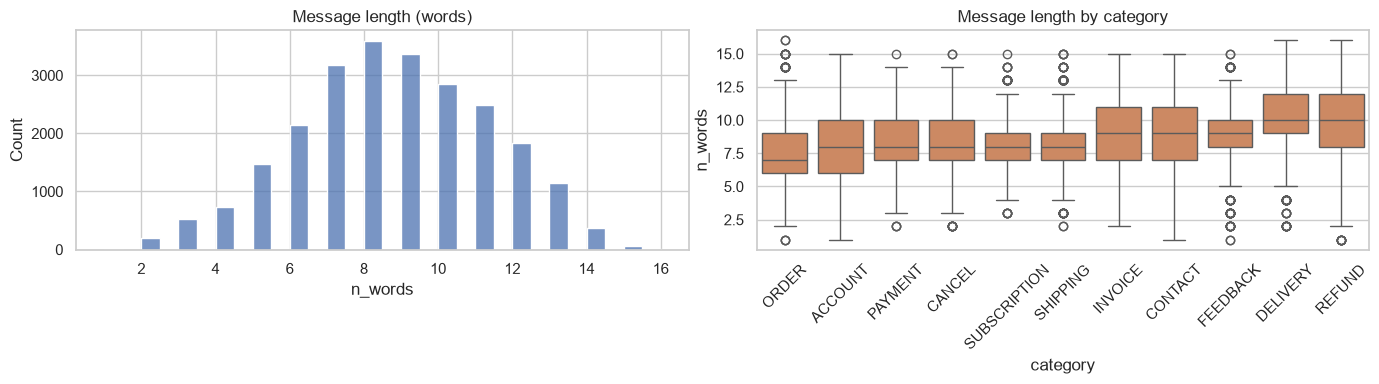

In [12]:
clean["n_words"] = clean["text"].str.split().str.len()
print(clean["n_words"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(clean["n_words"], bins=30, ax=axes[0], color="#4C72B0")
axes[0].set_title("Message length (words)")

order = clean.groupby("category")["n_words"].median().sort_values().index
sns.boxplot(data=clean, x="category", y="n_words", order=order, ax=axes[1], color="#DD8452")
axes[1].set_title("Message length by category")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 1️⃣2️⃣ Har category ke top words

**CountVectorizer** har word ko gin-ta hai. `stop_words="english"` se "the, is, a" jaise common words hat jaate hain.
Agar har category ke top words alag aur meaningful hain → model ke liye category pehchanna aasaan hoga ✅

In [13]:
from sklearn.feature_extraction.text import CountVectorizer

for cat in clean["category"].value_counts().index:
    texts = clean.loc[clean["category"] == cat, "text"]
    cv = CountVectorizer(stop_words="english", max_features=2000)
    counts = cv.fit_transform(texts).sum(axis=0).A1
    top = [cv.get_feature_names_out()[i] for i in counts.argsort()[::-1][:8]]
    print(f"{cat:<14} → {', '.join(top)}")

ACCOUNT        → account, help, need, user, know, want, profile, assistance
ORDER          → order, purchase, help, need, want, status, assistance, item
REFUND         → help, money, check, refund, ask, need, cases, request
FEEDBACK       → help, feedback, ur, claim, company, leave, complaint, need
PAYMENT        → payment, help, payments, online, options, need, methods, want
CONTACT        → customer, help, assistance, support, speak, talk, agent, service
SHIPPING       → address, shipping, delivery, help, need, set, new, secondary
INVOICE        → invoice, know, need, help, download, look, 37777, 12588
DELIVERY       → check, help, arrive, soon, expect, delivery, methods, shipment
SUBSCRIPTION   → newsletter, help, subscription, company, corporate, unsubscribe, cancel, need
CANCEL         → early, termination, check, help, exit, withdrawal, cancellation, penalty


## 1️⃣3️⃣ Clean data save karna
Training script (`ml/train.py`) isi file se padhegi.

In [14]:
clean[["text", "category", "intent"]].to_csv(CLEAN_PATH, index=False)
print("Saved:", CLEAN_PATH, "| rows:", len(clean))

Saved: D:\Capstone project\ml\data\bitext_clean.csv | rows: 23990


## ✅ Summary (viva ke liye)

- Dataset: **Bitext customer support**, ~27K messages, **11 categories** (e-commerce domain → demo company *ShopNest*)
- **Missing values:** check kiye
- **Duplicates + conflicting labels hataye** → data leakage se bachne ke liye
- **Placeholders hataye** → model placeholder ke naam se "cheat" na kare
- **Typos rakhe** → real customers jaisa messy text
- **Imbalance (~6x):** stratified split + balanced class weights + macro-F1 se handle karenge
- Har category ke top words alag hain → classification feasible hai

👉 **Next:** `ml/train.py` — TF-IDF + 3 models compare karke best model save karna.